# ToolLens: бейзлайны и все варианты loss/семплинга CF

        Реальные локальные данные, собственный групповой split 80/20 с seed=67.
        Официальные split сохраняются для аудита; это **не официальный результат ToolLens**.
        Настройки 12 конфигураций зафиксированы до test. Валидации и подбора нет.
        Близкие запросы (Jaccard множества токенов ≥0.9) соединяются транзитивно
        и целиком попадают в один split. Один seed ограничивает обобщаемость выводов.

In [1]:
# Окружение задаётся до импорта численных библиотек и энкодера.
import os
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'rankers').exists():
    ROOT = next(path for path in Path.cwd().parents if (path / 'rankers').exists())
RUNTIME = ROOT / 'output/jupyter-notebook/runtime'
for name, folder in [('MPLCONFIGDIR', 'mpl'), ('XDG_CACHE_HOME', 'cache'), ('IPYTHONDIR', 'ipython')]:
    location = RUNTIME / folder
    location.mkdir(parents=True, exist_ok=True)
    os.environ[name] = str(location)
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[name] = '4'
os.environ.update(USE_TF='0', USE_FLAX='0', USE_TORCH='1',
                  HF_HUB_OFFLINE='1', TRANSFORMERS_OFFLINE='1', TOKENIZERS_PARALLELISM='false')
import sys, json, platform, subprocess, time, uuid
from datetime import datetime, timezone
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from IPython.display import display
from threadpoolctl import threadpool_limits
torch.set_num_threads(4)
THREAD_LIMIT = threadpool_limits(limits=4)
from experiments.toollens_experiment import (validate_tables, near_duplicate_groups,
    grouped_split, query_metrics, bootstrap_metrics, PeakRSS, file_sha256, json_hash)
from rankers.popularity import PopularityRanker
from rankers.bm25 import BM25Ranker
from rankers.bge import ZeroShotBGERanker
from rankers.query_knn_cf import QueryKNNCFRanker
from rankers.family_query_knn_cf import FamilyQueryKNNCFRanker
from rankers.projected_query_cf import ProjectedQueryCFRanker

## Замороженный план

        Popularity, BM25 и BGE сравниваются с Query-KNN CF, Family CF и Projected CF.
        Все модели получают одинаковые train-запросы, позитивные train-связи и каталог.
        Для каждой из трёх CF-моделей запускаются MSE, BPR/random и BPR/semantic.
        MSE учитывает все нулевые train-пары и не использует семплинг: дублировать его
        для random/semantic бессмысленно. Для Popularity, BM25 и zero-shot BGE loss и
        семплинг неприменимы. Всего 3 бейзлайна + 9 CF-конфигураций; BGE заморожен.
        BPR/random выбирает негативы равномерно среди train API без позитивной связи.
        BPR/semantic следует текущему CF-протоколу: выбирает среди H наиболее далёких
        допустимых train API (минимальный cosine), а не среди ближайших hard negatives.
        Для Family CF исключаются все позитивы семейства. Строки без допустимых негативов
        пропускаются в BPR; отсутствие допустимых троек во всём наборе вызывает ошибку.
        Macro Recall, бинарный NDCG и FullCoverage строятся для K=1…20.
        Для K=3,5,10,20: парный bootstrap (1000, seed=68) и разности относительно BGE.
        Запросы без позитивов исключаются из средних с отдельным счётчиком.

In [2]:
SEED = 67
PROTOCOL = 'ToolLens-custom-grouped-80-20-seed67-loss-sampling-v2'
MODEL_PATH = ROOT / 'models/bge-small-en-v1.5'
INSTRUCTION = 'Represent this sentence for searching relevant passages: '
CF_COMMON = dict(factors=16, epochs=5, regularization=.1,
    positive_weight=1., n_neighbors=10, neighbor_weighting='cosine',
    seed=SEED, device='cpu', encoder_device='cpu', learning_rate=.01,
    batch_size=128, query_instruction=INSTRUCTION, max_length=512, encoder_batch_size=32)
CONFIGS = {
    'Popularity': {}, 'BM25': dict(k1=1.5, b=.75),
    'BGE': dict(model_path=str(MODEL_PATH), device='cpu', max_length=512,
                batch_size=32, query_instruction=INSTRUCTION),
}
BASELINE_NAMES = list(CONFIGS)
FACTORIES = {'Popularity': PopularityRanker, 'BM25': BM25Ranker, 'BGE': ZeroShotBGERanker}
CF_FAMILIES = {
    'Query-KNN CF': (QueryKNNCFRanker, {}),
    'Family CF': (FamilyQueryKNNCFRanker,
                  dict(clustering='minibatch_kmeans', n_families=64, aggregation='binary')),
    'Projected CF': (ProjectedQueryCFRanker, {}),
}
BPR_COMMON = dict(negatives_per_positive=1, hard_pool_size=20)
CF_OBJECTIVES = {
    'MSE': dict(loss='mse'),
    'BPR/random': dict(loss='bpr', negative_sampling='random', **BPR_COMMON),
    'BPR/semantic': dict(loss='bpr', negative_sampling='semantic', **BPR_COMMON),
}
VARIANTS = {name: dict(family=name, loss=None, negative_sampling=None) for name in BASELINE_NAMES}
for family, (factory, family_config) in CF_FAMILIES.items():
    for objective, objective_config in CF_OBJECTIVES.items():
        name = f'{family} | {objective}'
        CONFIGS[name] = dict(CF_COMMON, **family_config, **objective_config)
        FACTORIES[name] = factory
        VARIANTS[name] = dict(family=family, loss=objective_config['loss'],
                              negative_sampling=objective_config.get('negative_sampling'))
RUN_DIR = ROOT / 'output/jupyter-notebook/runs' / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8])
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR / 'configs.json').write_text(json.dumps(CONFIGS, ensure_ascii=False, indent=2), encoding='utf-8')
(RUN_DIR / 'variants.json').write_text(json.dumps(VARIANTS, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([{'model': name, **VARIANTS[name], **config}
                      for name, config in CONFIGS.items()]).fillna('—'))
print('Run:', RUN_DIR)

,model,family,loss,negative_sampling,k1,b,model_path,device,max_length,batch_size,...,neighbor_weighting,seed,encoder_device,learning_rate,encoder_batch_size,negatives_per_positive,hard_pool_size,clustering,n_families,aggregation
0,Popularity,Popularity,—,—,—,—,—,—,—,—,...,—,—,—,—,—,—,—,—,—,—
1,BM25,BM25,—,—,1.5,0.75,—,—,—,—,...,—,—,—,—,—,—,—,—,—,—
2,BGE,BGE,—,—,—,—,/Users/svatoslavpolonskiy/Codex/CFTSagent/mode...,cpu,512.0,32.0,...,—,—,—,—,—,—,—,—,—,—
3,Query-KNN CF | MSE,Query-KNN CF,mse,—,—,—,—,cpu,512.0,128.0,...,cosine,67.0,cpu,0.01,32.0,—,—,—,—,—
4,Query-KNN CF | BPR/random,Query-KNN CF,bpr,random,—,—,—,cpu,512.0,128.0,...,cosine,67.0,cpu,0.01,32.0,1.0,20.0,—,—,—
5,Query-KNN CF | BPR/semantic,Query-KNN CF,bpr,semantic,—,—,—,cpu,512.0,128.0,...,cosine,67.0,cpu,0.01,32.0,1.0,20.0,—,—,—
6,Family CF | MSE,Family CF,mse,—,—,—,—,cpu,512.0,128.0,...,cosine,67.0,cpu,0.01,32.0,—,—,minibatch_kmeans,64.0,binary
7,Family CF | BPR/random,Family CF,bpr,random,—,—,—,cpu,512.0,128.0,...,cosine,67.0,cpu,0.01,32.0,1.0,20.0,minibatch_kmeans,64.0,binary
8,Family CF | BPR/semantic,Family CF,bpr,semantic,—,—,—,cpu,512.0,128.0,...,cosine,67.0,cpu,0.01,32.0,1.0,20.0,minibatch_kmeans,64.0,binary
9,Projected CF | MSE,Projected CF,mse,—,—,—,—,cpu,512.0,128.0,...,cosine,67.0,cpu,0.01,32.0,—,—,—,—,—


Run: /Users/svatoslavpolonskiy/Codex/CFTSagent/output/jupyter-notebook/runs/20261118T185807Z_1bc29135


## Данные и проверки

        Исходные таблицы читаются без изменения. Некорректные ID, ссылки, пустые тексты,
        повторные пары и нечисловые метки завершают запуск ошибкой. Никакие строки не исключаются молча.

In [3]:
DATA_DIR = ROOT / 'data/ToolLens/processed'
tables = {}
with PeakRSS() as measurement:
    for name in tqdm(['apis', 'requests', 'interactions'], desc='Чтение Parquet'):
        tables[name] = pd.read_parquet(DATA_DIR / (name + '.parquet'))
    apis, requests, interactions = (tables[name] for name in ['apis', 'requests', 'interactions'])
    validation = validate_tables(apis, requests, interactions)
resources = {'load_and_validate': measurement.record()}
data_hashes = {name: file_sha256(DATA_DIR / (name + '.parquet')) for name in tables}
requests = requests.rename(columns={'split': 'source_split'}).copy()
display(pd.DataFrame([validation]))
display(requests.source_split.value_counts().rename('queries').to_frame())

Чтение Parquet:   0%|          | 0/3 [00:00<?, ?it/s]

,apis,requests,interactions,no_positive_queries
0,464,18770,49852,0


,queries
source_split,
train,15016
val,1877
test,1877


## Группы и независимый test

        Unicode NFKC, casefold, токены `\w+`, цифры сохраняются. Exact prefix join с
        глобальным порядком редкости и фильтром размера проверяет все допустимые пары.
        Нет случайного сэмплирования пар, матрицы N×N или ограничения числа кандидатов.
        Граница train выбирается по ближайшему к 80% числу запросов после перемешивания групп.

In [4]:
with PeakRSS() as measurement:
    with tqdm(total=len(requests), desc='Точный near-duplicate join') as bar:
        groups = near_duplicate_groups(requests.Request_id.tolist(), requests.text.tolist(),
            threshold=.9, progress=lambda step, total: bar.update(step - bar.n))
    split = grouped_split(groups, seed=SEED, train_fraction=.8)
resources['grouping'] = measurement.record()
requests['group_id'] = requests.Request_id.map(groups)
requests['split'] = requests.Request_id.map(split)
assert requests.groupby('group_id')['split'].nunique().max() == 1
split_hash = json_hash(sorted(split.items()))
requests[['Request_id', 'group_id', 'source_split', 'split']].to_csv(RUN_DIR / 'split_ids.csv', index=False)
group_sizes = requests.groupby('group_id').size()
display(requests.groupby('split').agg(queries=('Request_id','size'), groups=('group_id','nunique')))
print('Компонент >1 запроса:', int((group_sizes > 1).sum()), '; максимальная:', int(group_sizes.max()))
print('Split SHA256:', split_hash)
full_corpus = {int(row.API_id): {'description': row.description} for row in apis.itertuples(index=False)}
train_frame = requests[requests.split == 'train'].sort_values('Request_id')
test_frame = requests[requests.split == 'test'].sort_values('Request_id')
if train_frame.empty or test_frame.empty:
    raise ValueError('Групповой split должен иметь непустые train и test')
train_queries = dict(zip(map(int, train_frame.Request_id), train_frame.text))
test_queries = dict(zip(map(int, test_frame.Request_id), test_frame.text))
train_qrels = {identifier: {} for identifier in train_queries}
test_qrels = {identifier: set() for identifier in test_queries}
for row in interactions.itertuples(index=False):
    if row.relevance > 0:
        if int(row.Request_id) in train_qrels:
            train_qrels[int(row.Request_id)][int(row.API_id)] = float(row.relevance)
        else:
            test_qrels[int(row.Request_id)].add(int(row.API_id))
train_api_ids = set(api for links in train_qrels.values() for api in links)
train_corpus = {api: full_corpus[api] for api in sorted(train_api_ids)}
if not train_corpus or not any(test_qrels.values()):
    raise ValueError('Нужны позитивные API в train и хотя бы один test-запрос с позитивами')
print('Train API / полный каталог:', len(train_corpus), '/', len(full_corpus))
print('Запросы без позитивов train/test:', sum(not v for v in train_qrels.values()), sum(not v for v in test_qrels.values()))

Точный near-duplicate join:   0%|          | 0/18770 [00:00<?, ?it/s]

,queries,groups
split,,
test,3754,3729
train,15016,14843


Компонент >1 запроса: 98 ; максимальная: 38
Split SHA256: 087950a3fffa6d7f27629903043d985d5012027267bc62dde21dcefb8dc3ce21
Train API / полный каталог: 464 / 464
Запросы без позитивов train/test: 0 0


## Один локальный замороженный энкодер

        Описания API и train/test-запросы кодируются общими батчами. Test-эмбеддинги
        используются только при инференсе. Стоимость общего кодирования учитывается отдельно.
        Полный каталог доступен всем моделям, включая API без train-истории.

In [5]:
from sentence_transformers import SentenceTransformer
with PeakRSS() as measurement:
    encoder = SentenceTransformer(str(MODEL_PATH), device='cpu', local_files_only=True)
    encoder.max_seq_length = 512
resources['encoder_load'] = measurement.record()
def encode_cache(mapping, prefix, label):
    identifiers = sorted(mapping)
    batches = []
    for offset in tqdm(range(0, len(identifiers), 32), desc=label):
        ids = identifiers[offset:offset + 32]
        batch = encoder.encode([prefix + mapping[key] for key in ids],
            batch_size=32, show_progress_bar=False, convert_to_numpy=True)
        batches.append(np.asarray(batch, dtype=np.float32))
    matrix = np.concatenate(batches)
    return identifiers, matrix, {key: row for key, row in zip(identifiers, matrix)}
with PeakRSS() as measurement:
    api_ids, api_matrix, api_cache = encode_cache({key: doc['description'] for key, doc in full_corpus.items()}, '', 'API')
    train_ids, train_matrix, train_cache = encode_cache(train_queries, INSTRUCTION, 'Train-запросы')
    test_ids, test_matrix, test_cache = encode_cache(test_queries, INSTRUCTION, 'Test-запросы (инференс)')
resources['shared_encoding'] = measurement.record()
np.savez_compressed(RUN_DIR / 'embeddings.npz', api_ids=api_ids, api_embeddings=api_matrix,
    train_ids=train_ids, train_embeddings=train_matrix, test_ids=test_ids, test_embeddings=test_matrix)
lookup = {full_corpus[key]['description']: value for key, value in api_cache.items()}
lookup.update({INSTRUCTION + train_queries[key]: value for key, value in train_cache.items()})
lookup.update({INSTRUCTION + test_queries[key]: value for key, value in test_cache.items()})
class CachedEncoder:
    def encode(self, texts):
        return np.stack([lookup[text] for text in texts])
cached_encoder = CachedEncoder()

API:   0%|          | 0/15 [00:00<?, ?it/s]

Train-запросы:   0%|          | 0/470 [00:00<?, ?it/s]

Test-запросы (инференс):   0%|          | 0/118 [00:00<?, ?it/s]

## Обучение на train и ранжирование полного каталога

        Индикатор CF обновляется после каждой реальной эпохи. Общая стоимость BGE
        не включается повторно в каждую модель; fit/prepare/predict учитываются отдельно.

In [6]:
models, predictions, metric_rows, loss_rows, model_resources = {}, [], [], [], {}
catalogue = set(full_corpus)
# Семантические негативы используют ровно train API, включая при неполном покрытии.
train_api_cache = {identifier: api_cache[identifier] for identifier in sorted(train_corpus)}
for name, factory in tqdm(FACTORIES.items(), desc='12 конфигураций'):
    config = dict(CONFIGS[name])
    is_cf = VARIANTS[name]['loss'] is not None
    if name not in ['Popularity', 'BM25']:
        config['encoder'] = cached_encoder
    model = factory(**config)
    fit_kwargs = dict(train_queries=train_queries)
    if is_cf:
        fit_kwargs['train_query_embeddings'] = train_cache
        if config['loss'] == 'bpr' and config['negative_sampling'] == 'semantic':
            fit_kwargs['train_api_embeddings'] = train_api_cache
        with tqdm(total=config['epochs'], desc=name + ' эпохи') as bar:
            def on_epoch(epoch, loss):
                bar.update(epoch - bar.n)
                bar.set_postfix(loss=f'{loss:.6f}')
            with PeakRSS() as measurement:
                model.fit(train_corpus, train_qrels, progress_callback=on_epoch, **fit_kwargs)
    else:
        with PeakRSS() as measurement:
            model.fit(train_corpus, train_qrels, **fit_kwargs)
    fit_resource = measurement.record()
    with PeakRSS() as measurement:
        model.prepare_candidates(full_corpus)
    prepare_resource = measurement.record()
    rankings = []
    with PeakRSS() as measurement:
        for identifier, text in tqdm(test_queries.items(), desc=name + ' test', leave=False):
            ranking = model.predict_from_embedding(test_cache[identifier], 20) if is_cf else model.predict(text, 20)
            rankings.append((identifier, ranking))
    predict_resource = measurement.record()
    with PeakRSS() as measurement:
        for identifier, ranking in tqdm(rankings, desc=name + ' метрики', leave=False):
            if len(ranking) != min(20, len(catalogue)) or len(ranking) != len(set(ranking)) or not set(ranking) <= catalogue:
                raise ValueError('Недопустимое ранжирование полного каталога')
            predictions.append(dict(model=name, Request_id=identifier, ranked_api_ids=ranking))
            scores = query_metrics(ranking, test_qrels[identifier])
            if scores is not None:
                metric_rows.extend(dict(model=name, Request_id=identifier, metric=metric, k=k, value=value)
                                   for (metric, k), value in scores.items())
    evaluate_resource = measurement.record()
    model_resources[name] = dict(fit=fit_resource, prepare_candidates=prepare_resource,
        predict=predict_resource, evaluate=evaluate_resource)
    if is_cf:
        loss_rows.extend(dict(model=name, **VARIANTS[name], epoch=epoch, value=value)
                         for epoch, value in enumerate(model.loss_history_, 1))
    models[name] = model
per_query = pd.DataFrame(metric_rows)
losses = pd.DataFrame(loss_rows)
summary = per_query.groupby(['model','metric','k'], as_index=False).value.mean()
pd.DataFrame(predictions).to_json(RUN_DIR / 'predictions.jsonl', orient='records', lines=True)
per_query.to_parquet(RUN_DIR / 'per_query_metrics.parquet', index=False)
summary.to_csv(RUN_DIR / 'summary_curves.csv', index=False)
losses.to_csv(RUN_DIR / 'losses.csv', index=False)
display(summary[summary.k.isin([3,5,10,20])].pivot(index=['model','k'], columns='metric', values='value').round(4))

12 конфигураций:   0%|          | 0/12 [00:00<?, ?it/s]

Popularity test:   0%|          | 0/3754 [00:00<?, ?it/s]

Popularity метрики:   0%|          | 0/3754 [00:00<?, ?it/s]

BM25 test:   0%|          | 0/3754 [00:00<?, ?it/s]

BM25 метрики:   0%|          | 0/3754 [00:00<?, ?it/s]

BGE test:   0%|          | 0/3754 [00:00<?, ?it/s]

... (25 outputs left out)

Projected CF | BPR/semantic эпохи:   0%|          | 0/5 [00:00<?, ?it/s]

Projected CF | BPR/semantic test:   0%|          | 0/3754 [00:00<?, ?it/s]

Projected CF | BPR/semantic метрики:   0%|          | 0/3754 [00:00<?, ?it/s]

metric                          FullCoverage    NDCG  Recall
model                       k                               
BGE                         3         0.0733  0.2859  0.2712
                            5         0.1066  0.3220  0.3377
                            10        0.1705  0.3665  0.4411
                            20        0.2584  0.4036  0.5507
BM25                        3         0.0464  0.2631  0.2390
                            5         0.0791  0.2935  0.2951
                            10        0.1095  0.3186  0.3536
                            20        0.1553  0.3423  0.4237
Family CF | BPR/random      3         0.0016  0.1267  0.1282
                            5         0.0045  0.1476  0.1657
                            10        0.0400  0.1895  0.2629
                            20        0.1185  0.2474  0.4334
Family CF | BPR/semantic    3         0.0048  0.1173  0.1139
                            5         0.0083  0.1455  0.1644
                            10        0.0178  0.1813  0.2465
                            20        0.0605  0.2164  0.3492
Family CF | MSE             3         0.0053  0.1883  0.1933
                            5         0.0250  0.2346  0.2769
                            10        0.0898  0.2853  0.3938
                            20        0.2493  0.3429  0.5620
Popularity                  3         0.0000  0.1621  0.1445
                            5         0.0021  0.1799  0.1763
                            10        0.0051  0.2085  0.2401
                            20        0.0149  0.2415  0.3357
Projected CF | BPR/random   3         0.0765  0.4629  0.4477
                            5         0.2080  0.5399  0.5871
                            10        0.5301  0.6251  0.7835
                            20        0.8127  0.6699  0.9166
Projected CF | BPR/semantic 3         0.0059  0.2385  0.2212
                            5         0.0157  0.2740  0.2847
                            10        0.0703  0.3293  0.4109
                            20        0.1542  0.3685  0.5255
Projected CF | MSE          3         0.0210  0.4026  0.3495
                            5         0.0466  0.4320  0.4018
                            10        0.1359  0.4713  0.4909
                            20        0.3183  0.5131  0.6137
Query-KNN CF | BPR/random   3         0.2952  0.7007  0.6660
                            5         0.5493  0.7682  0.7851
                            10        0.7762  0.8105  0.8780
                            20        0.8660  0.8241  0.9173
Query-KNN CF | BPR/semantic 3         0.0967  0.4602  0.4449
                            5         0.1990  0.5216  0.5566
                            10        0.3524  0.5812  0.6922
                            20        0.5647  0.6194  0.8029
Query-KNN CF | MSE          3         0.0242  0.4434  0.3844
                            5         0.0562  0.4767  0.4438
                            10        0.1870  0.5224  0.5472
                            20        0.4494  0.5670  0.6761

## Парная неопределённость и покрытие

        Все модели используют одни и те же bootstrap-веса. Помимо query-bootstrap,
        при наличии близких компонент показываем cluster-bootstrap целых групп.
        Покрытие полного каталога и train-истории учитывается раздельно.

In [7]:
selected_metrics = per_query[per_query.k.isin([3,5,10,20])]
interval_frames = []
modes = [('query', None)]
if (group_sizes > 1).any():
    modes.append(('group', groups))
with PeakRSS() as measurement:
    for mode, resample_groups in tqdm(modes, desc='Парный bootstrap ×1000'):
        frame = bootstrap_metrics(selected_metrics, n_bootstrap=1000, seed=68, groups=resample_groups)
        frame['resampling'] = mode
        interval_frames.append(frame)
resources['bootstrap'] = measurement.record()
intervals = pd.concat(interval_frames, ignore_index=True)
intervals.to_csv(RUN_DIR / 'intervals_and_paired_differences.csv', index=False)
covered = []
for identifier, positives in test_qrels.items():
    if positives:
        covered.append(dict(Request_id=identifier, positives=len(positives),
            full_found=len(positives & catalogue), train_found=len(positives & train_api_ids)))
coverage_rows = pd.DataFrame(covered)
coverage = dict(full_catalogue_size=len(catalogue), train_history_size=len(train_api_ids),
    test_queries=len(test_queries), evaluated_queries=len(covered),
    excluded_no_positive_queries=sum(not value for value in test_qrels.values()),
    full_catalogue_micro=coverage_rows.full_found.sum()/coverage_rows.positives.sum(),
    full_catalogue_macro=(coverage_rows.full_found/coverage_rows.positives).mean(),
    train_history_micro=coverage_rows.train_found.sum()/coverage_rows.positives.sum(),
    train_history_macro=(coverage_rows.train_found/coverage_rows.positives).mean())
coverage_rows.to_csv(RUN_DIR / 'coverage_by_query.csv', index=False)
display(pd.DataFrame([coverage]))
display(intervals[(intervals.k == 10) & (intervals.metric == 'FullCoverage')].round(4))

Парный bootstrap ×1000:   0%|          | 0/2 [00:00<?, ?it/s]

,full_catalogue_size,train_history_size,test_queries,evaluated_queries,excluded_no_positive_queries,full_catalogue_micro,full_catalogue_macro,train_history_micro,train_history_macro
0,464,464,3754,3754,0,1.0,1.0,1.0,1.0


,model,metric,k,mean,low,high,difference,delta_low,delta_high,resampling
8,Popularity,FullCoverage,10,0.0051,0.0029,0.0075,-0.1654,-0.1774,-0.1529,query
20,BM25,FullCoverage,10,0.1095,0.0996,0.1199,-0.0610,-0.0717,-0.0493,query
32,BGE,FullCoverage,10,0.1705,0.1580,0.1825,0.0000,0.0000,0.0000,query
44,Query-KNN CF | MSE,FullCoverage,10,0.1870,0.1755,0.1993,0.0165,-0.0013,0.0349,query
56,Query-KNN CF | BPR/random,FullCoverage,10,0.7762,0.7640,0.7901,0.6058,0.5903,0.6220,query
68,Query-KNN CF | BPR/semantic,FullCoverage,10,0.3524,0.3378,0.3660,0.1819,0.1657,0.1971,query
80,Family CF | MSE,FullCoverage,10,0.0898,0.0812,0.0996,-0.0807,-0.0959,-0.0650,query
92,Family CF | BPR/random,FullCoverage,10,0.0400,0.0344,0.0466,-0.1305,-0.1433,-0.1172,query
104,Family CF | BPR/semantic,FullCoverage,10,0.0178,0.0139,0.0221,-0.1526,-0.1654,-0.1398,query
116,Projected CF | MSE,FullCoverage,10,0.1359,0.1249,0.1476,-0.0346,-0.0506,-0.0184,query


## Кривые качества и реальные функции потерь

        Один общий рисунок содержит все 12 конфигураций: слева Recall@K,
        в центре NDCG@K, справа FullCoverage@K. Ось X — K от 1 до 20.
        Три бейзлайна — Popularity, BM25 и BGE. Для каждого семейства Query-KNN CF,
        Family CF и Projected CF показаны MSE, BPR/random и BPR/semantic.
        Цвет обозначает семейство модели; для CF сплошная линия означает MSE,
        штриховая — BPR/random, точечная — BPR/semantic. Легенда общая для трёх панелей.
        Если метрики какой-либо конфигурации ещё не рассчитаны, код сообщает об этом
        вместо молчаливого построения неполного сравнения.
        Истории MSE и BPR показаны на разных осях: их абсолютные значения несопоставимы.
        В loss-таблице тип цели хранится в loss, а её численное значение — в value.

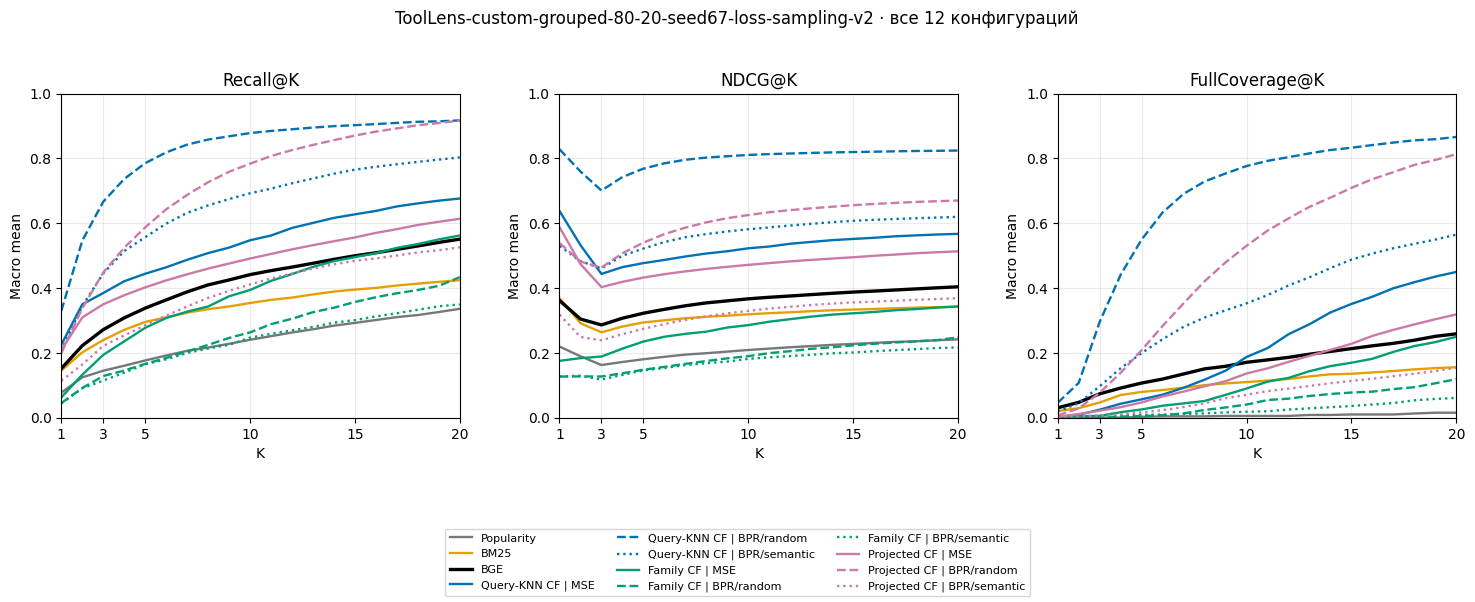

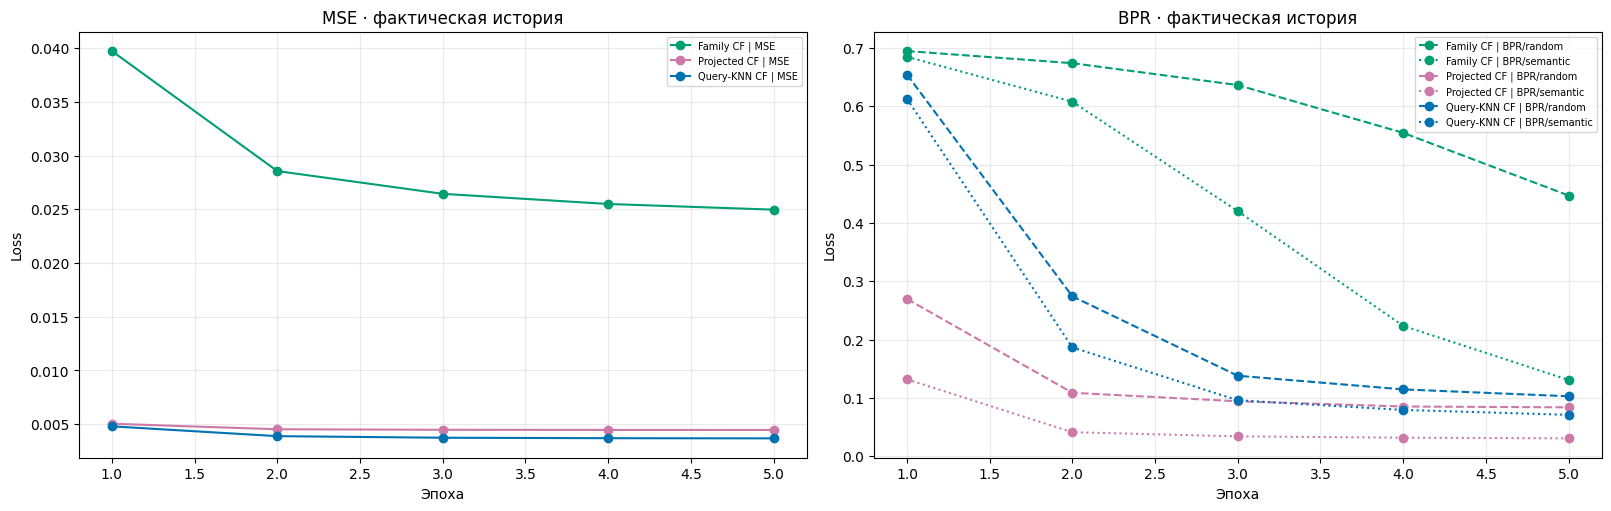

In [8]:
model_order = list(FACTORIES)
missing_models = set(model_order) - set(summary['model'])
if missing_models:
    raise ValueError('Ещё не рассчитаны метрики конфигураций: ' + ', '.join(sorted(missing_models)))
family_colors = {
    'Popularity': '#777777', 'BM25': '#E69F00', 'BGE': '#000000',
    'Query-KNN CF': '#0072B2', 'Family CF': '#009E73', 'Projected CF': '#CC79A7',
}
objective_styles = {('mse', None): '-', ('bpr', 'random'): '--', ('bpr', 'semantic'): ':'}
metric_panels = [('Recall', 'Recall@K'), ('NDCG', 'NDCG@K'), ('FullCoverage', 'FullCoverage@K')]
figure, axes = plt.subplots(1, 3, figsize=(18,6))
figure.subplots_adjust(bottom=.30, top=.84, wspace=.25)
for axis, (metric, title) in zip(axes, metric_panels):
    for name in model_order:
        curve = summary[(summary.model == name) & (summary.metric == metric)].sort_values('k')
        if len(curve) != 20 or set(curve.k) != set(range(1,21)):
            raise ValueError(f'Неполная кривая {metric} для {name}: нужны K=1…20')
        variant = VARIANTS[name]
        style = objective_styles.get((variant['loss'], variant['negative_sampling']), '-')
        axis.plot(curve.k, curve.value, color=family_colors[variant['family']],
            linestyle=style, linewidth=2.4 if name == 'BGE' else 1.7, label=name)
    axis.set(title=title, xlabel='K', ylabel='Macro mean', xlim=(1,20), ylim=(0,1))
    axis.set_xticks([1,3,5,10,15,20])
    axis.grid(alpha=.25)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc='lower center', ncol=3, fontsize=8)
figure.suptitle(PROTOCOL + ' · все 12 конфигураций')
figure.savefig(RUN_DIR / 'all_models_metrics.png', dpi=160, bbox_inches='tight')
display(figure)
plt.close(figure)
figure, axes = plt.subplots(1, 2, figsize=(16,5), constrained_layout=True)
for axis, objective in zip(axes, ['mse', 'bpr']):
    for name, curve in losses[losses.loss == objective].groupby('model'):
        curve = curve.sort_values('epoch')
        variant = VARIANTS[name]
        style = objective_styles[(variant['loss'], variant['negative_sampling'])]
        axis.plot(curve.epoch, curve.value, marker='o', linestyle=style,
            color=family_colors[variant['family']], label=name)
    axis.set(title=objective.upper() + ' · фактическая история', xlabel='Эпоха', ylabel='Loss')
    axis.legend(fontsize=7); axis.grid(alpha=.25)
figure.savefig(RUN_DIR / 'cf_losses.png', dpi=160)
display(figure); plt.close(figure)

## Manifest и ограничения

        Сохранены все предсказания, метрики по запросам, доверительные интервалы,
        конфигурации, ID групп и split, хэши данных/кода/весов, время и выборочный RSS.
        Это реальный эксперимент на одном собственном разбиении без настройки параметров.
        Неполная разметка ограничивает интерпретацию; offline-метрики не доказывают успех LLM-агента.

In [9]:
import importlib.metadata
source_paths = list((ROOT / 'rankers').glob('*.py')) + [ROOT / 'experiments/toollens_experiment.py', ROOT / 'experiments/build_toollens_notebook.py', ROOT / 'experiments/run_notebook.py']
source_hashes = {str(path.relative_to(ROOT)): file_sha256(path) for path in source_paths}
model_hashes = {str(path.relative_to(MODEL_PATH)): file_sha256(path)
                for path in sorted(MODEL_PATH.rglob('*')) if path.is_file()}
notebook_source = json.loads((ROOT / 'experiments/toollens_ranker_experiments.ipynb').read_text())
code_cells_hash = json_hash([cell['source'] for cell in notebook_source['cells'] if cell['cell_type'] == 'code'])
manifest = dict(protocol=PROTOCOL, real_data=True, seed=SEED, bootstrap_seed=68,
    bootstrap_resamples=1000, no_validation_or_tuning=True, frozen_configs=CONFIGS,
    model_variants=VARIANTS,
    split_hash=split_hash, data_hashes=data_hashes, source_hashes=source_hashes,
    model_hashes=model_hashes, notebook_code_hash=code_cells_hash,
    git_head=subprocess.check_output(['git','rev-parse','HEAD'], cwd=ROOT, text=True).strip(),
    python=sys.version, platform=platform.platform(), threads=4,
    versions={name: importlib.metadata.version(name) for name in
              ['numpy','pandas','scipy','scikit-learn','torch','sentence-transformers','transformers']},
    encoder_revision='local-files-hashed', query_instruction=INSTRUCTION,
    validation=validation, coverage=coverage, resources=resources, models=model_resources,
    created_utc=datetime.now(timezone.utc).isoformat(), run_directory=str(RUN_DIR))
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([dict(model=name, stage=stage, **values)
    for name, stages in model_resources.items() for stage, values in stages.items()]))
print('Артефакты:', RUN_DIR)
print('Настройки после просмотра test не менялись.')

,model,stage,seconds,baseline_rss_bytes,peak_rss_bytes,peak_increase_bytes,sampling_interval_seconds
0,Popularity,fit,0.029297,1480704000,1480736768,32768,0.02
1,Popularity,prepare_candidates,0.000763,1480704000,1480736768,32768,0.02
2,Popularity,predict,0.006262,1480704000,1481719808,1015808,0.02
3,Popularity,evaluate,0.717984,1481687040,1533231104,51544064,0.02
4,BM25,fit,0.032884,1533214720,1536606208,3391488,0.02
5,BM25,prepare_candidates,0.020458,1536573440,1538441216,1867776,0.02
6,BM25,predict,0.165457,1538408448,1538932736,524288,0.02
7,BM25,evaluate,0.718979,1538899968,1589673984,50774016,0.02
8,BGE,fit,0.018868,1589641216,1589673984,32768,0.02
9,BGE,prepare_candidates,0.004486,1589641216,1589673984,32768,0.02


Артефакты: /Users/svatoslavpolonskiy/Codex/CFTSagent/output/jupyter-notebook/runs/20261118T185807Z_1bc29135
Настройки после просмотра test не менялись.
